In [ ]:
%load_ext cudf.pandas
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import drive

from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout, Input
from keras.callbacks import EarlyStopping
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Load Nifty50 data
FILE = "low_esg_portfolio.xlsx"
INDEX = "index" if FILE in ["high_esg_portfolio.xlsx", "low_esg_portfolio.xlsx"] else "niftyindex"
nifty = pd.read_excel('/content/drive/My Drive/DOP_Data/' + FILE)
nifty['Date'] = pd.to_datetime(nifty['date'])
nifty.set_index('Date', inplace=True)

# Load macroeconomic variables
macro = pd.read_excel('/content/drive/My Drive/DOP_Data/macroecon_vars.xlsx')
macro['Date'] = pd.to_datetime(macro['Month'])
macro.set_index('Date', inplace=True)

# Resample macro data to daily frequency (forward fill)
macro_daily = macro.resample('D').ffill()

# Merge datasets
data = pd.merge(nifty, macro_daily, left_index=True, right_index=True, how='inner')

# sort data correctly
data = data.sort_index(ascending=True)

In [ ]:
# Select features (Close price + macro vars + VIX_Close)
features = [INDEX] + [col for col in macro.columns if col not in ['Month', 'Date']] # + ['VIX_Close']
dataset = data[features]

# Scale data
scaler = MinMaxScaler()

# Drop Date column if it's still in dataset (this was causing the error as 'Month' was not dropped)
# The 'Month' column is now excluded directly from the features list
dataset_no_date = dataset.copy() # No need to drop 'date' or 'Month' explicitly here if features are selected correctly

# Scale only numeric columns
scaled_data = scaler.fit_transform(dataset_no_date)

# Convert back to DataFrame
scaled_df = pd.DataFrame(scaled_data, index=dataset.index, columns=dataset_no_date.columns)

In [ ]:
def create_sequences(data, seq_length=60):
    X, y = [], []
    for i in range(len(data) - seq_length):
        X.append(data[i:i+seq_length])
        y.append(data[i+seq_length, 0])  # predict Close price
    return np.array(X), np.array(y)




## SINGLE LAYER

Training: SL=30, N=150, D=0.2, OPT=adam, BS=8, LR = 0.001, ITER = 1


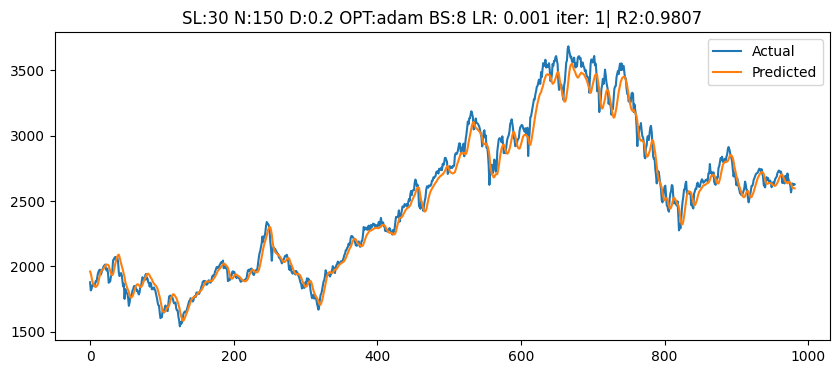

Training: SL=30, N=150, D=0.2, OPT=adam, BS=8, LR = 0.001, ITER = 2


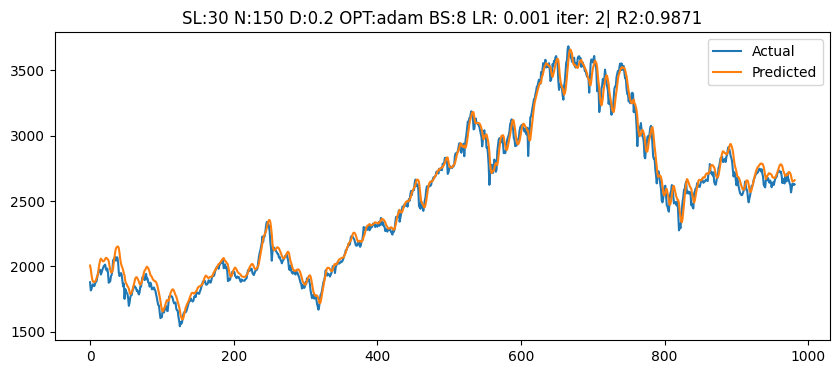

Training: SL=30, N=150, D=0.2, OPT=adam, BS=8, LR = 0.001, ITER = 3


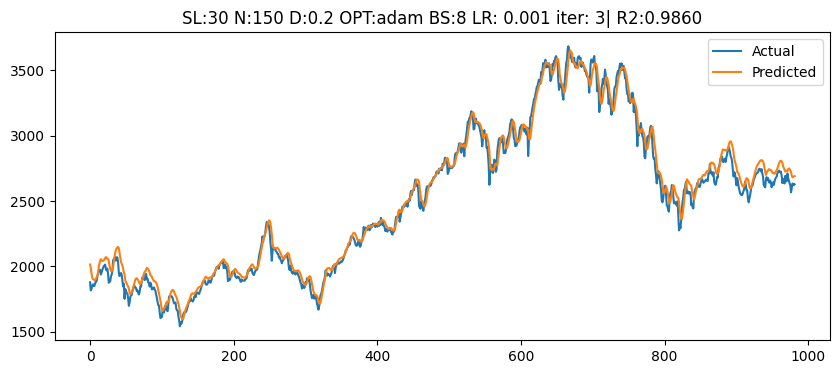

Training: SL=30, N=150, D=0.2, OPT=adam, BS=16, LR = 0.001, ITER = 1


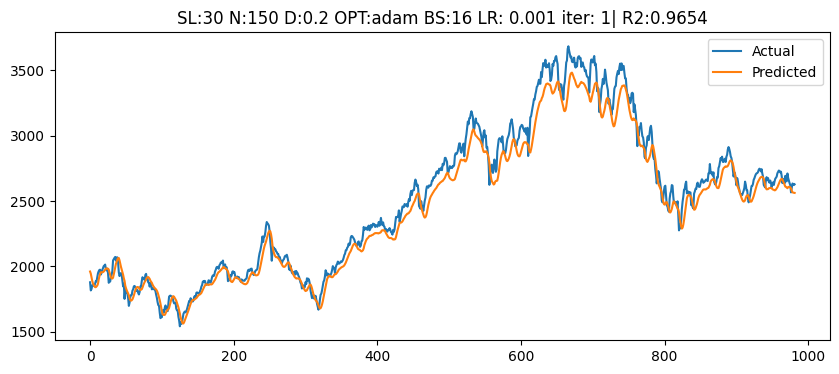

Training: SL=30, N=150, D=0.2, OPT=adam, BS=16, LR = 0.001, ITER = 2


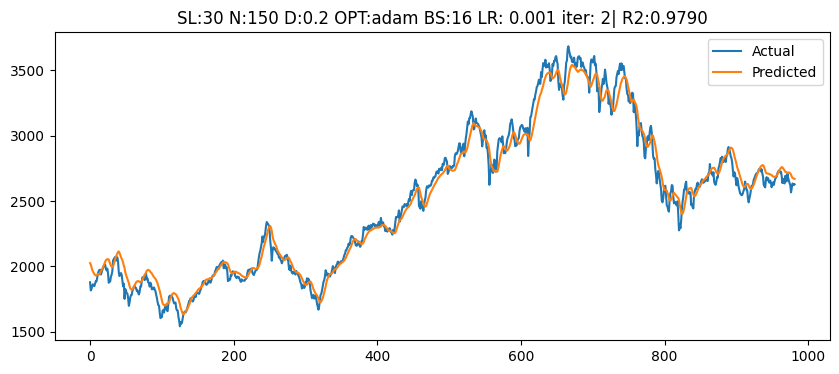

Training: SL=30, N=150, D=0.2, OPT=adam, BS=16, LR = 0.001, ITER = 3


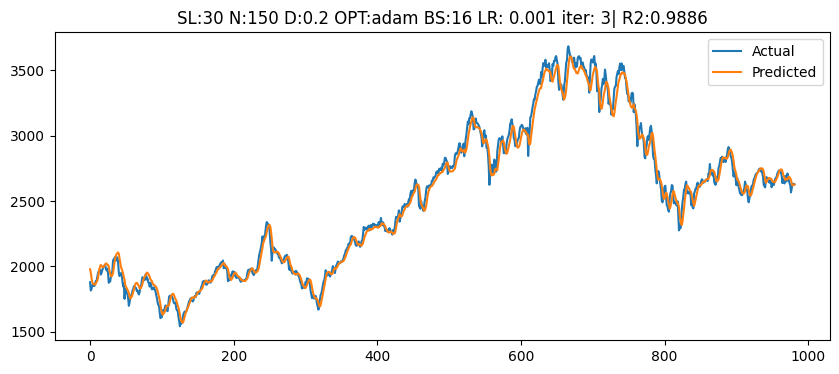

Training: SL=30, N=150, D=0.2, OPT=adam, BS=8, LR = 0.01, ITER = 1


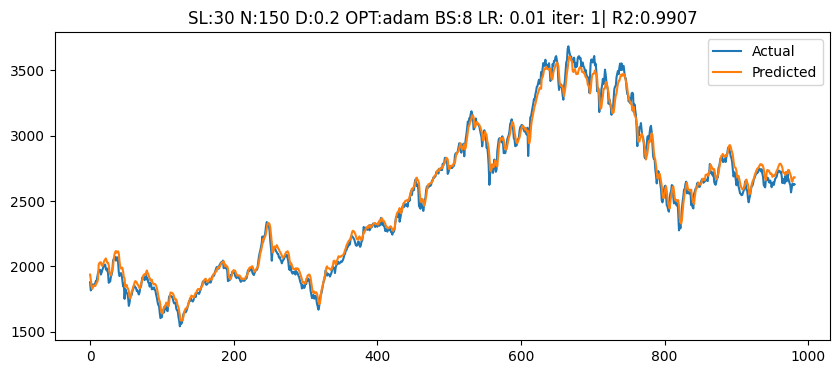

Training: SL=30, N=150, D=0.2, OPT=adam, BS=8, LR = 0.01, ITER = 2


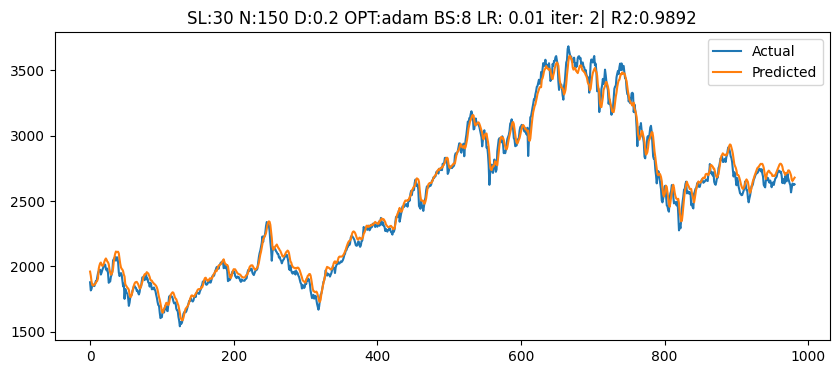

Training: SL=30, N=150, D=0.2, OPT=adam, BS=8, LR = 0.01, ITER = 3


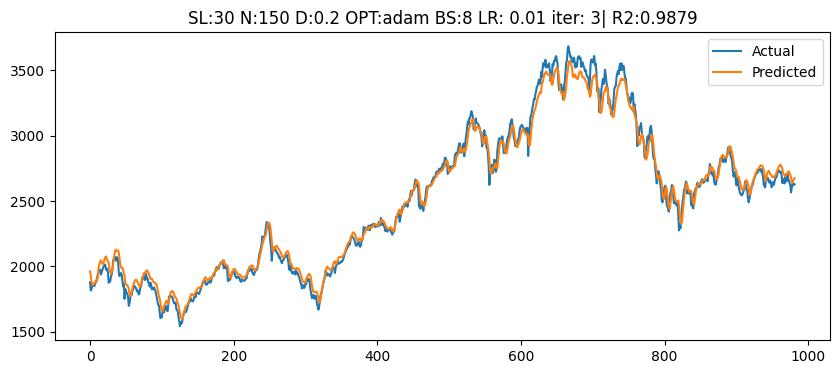

Training: SL=30, N=150, D=0.2, OPT=adam, BS=16, LR = 0.01, ITER = 1


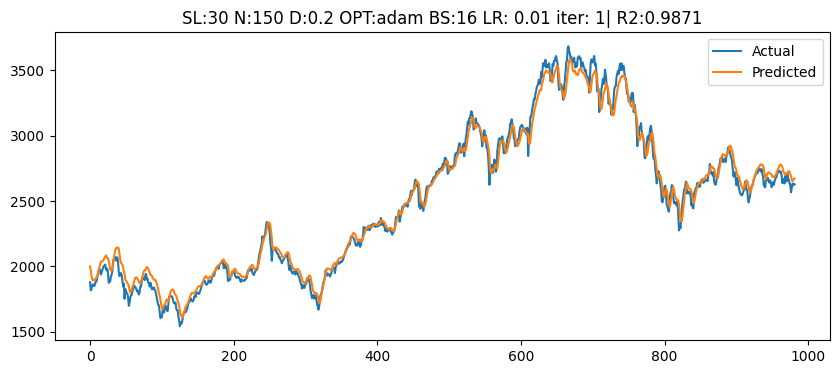

Training: SL=30, N=150, D=0.2, OPT=adam, BS=16, LR = 0.01, ITER = 2


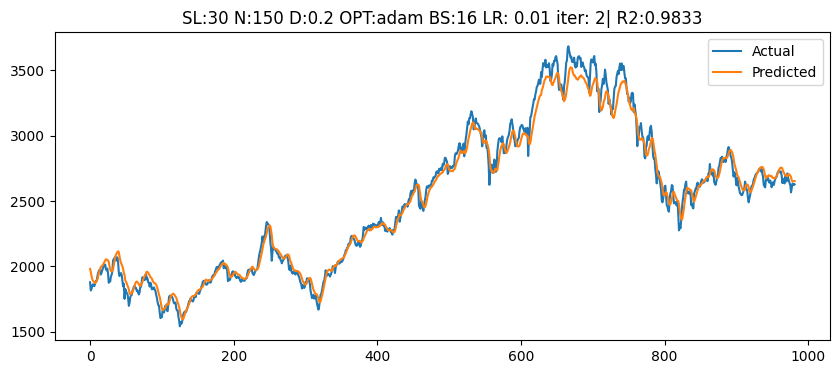

Training: SL=30, N=150, D=0.2, OPT=adam, BS=16, LR = 0.01, ITER = 3


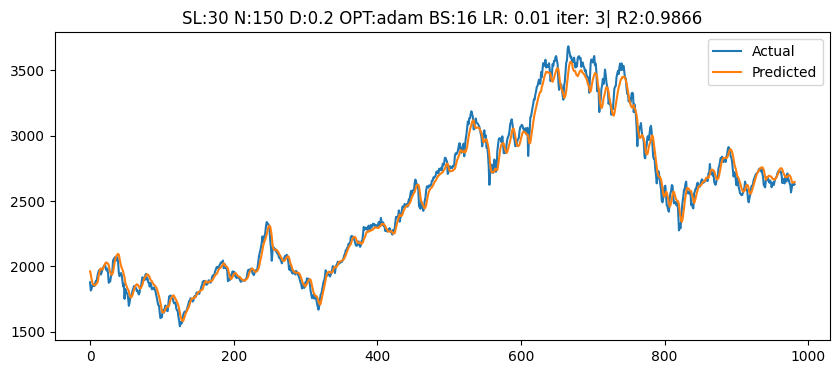

Training: SL=30, N=150, D=0.2, OPT=nadam, BS=8, LR = 0.001, ITER = 1


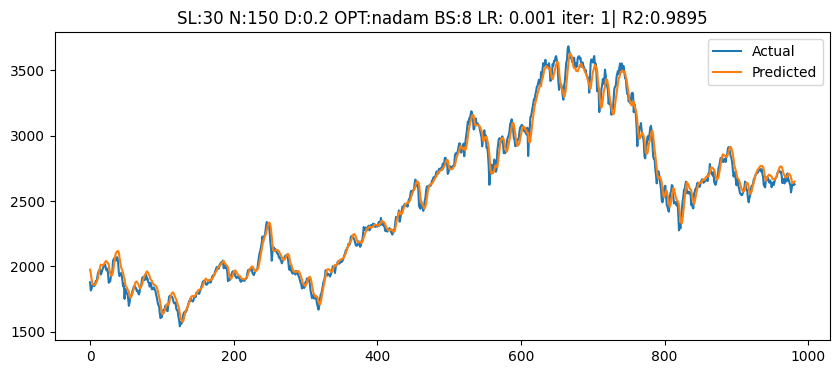

Training: SL=30, N=150, D=0.2, OPT=nadam, BS=8, LR = 0.001, ITER = 2


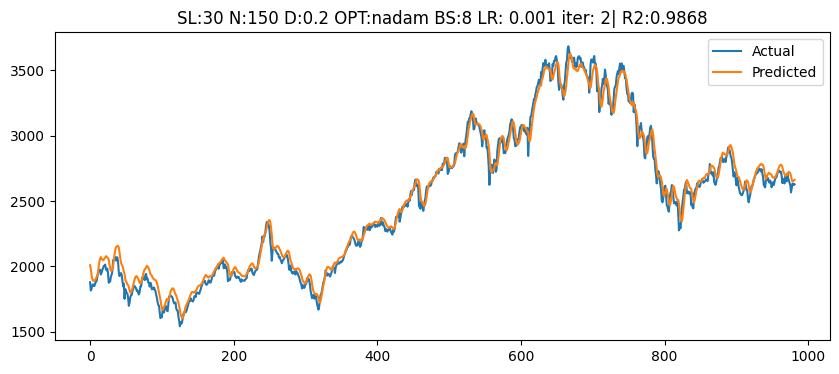

Training: SL=30, N=150, D=0.2, OPT=nadam, BS=8, LR = 0.001, ITER = 3


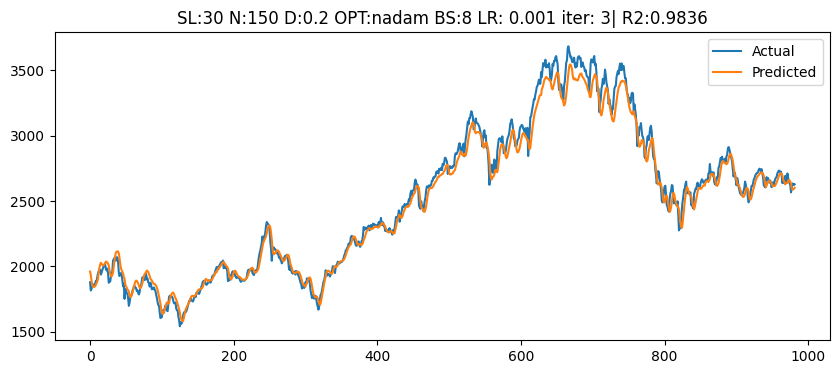

Training: SL=30, N=150, D=0.2, OPT=nadam, BS=16, LR = 0.001, ITER = 1


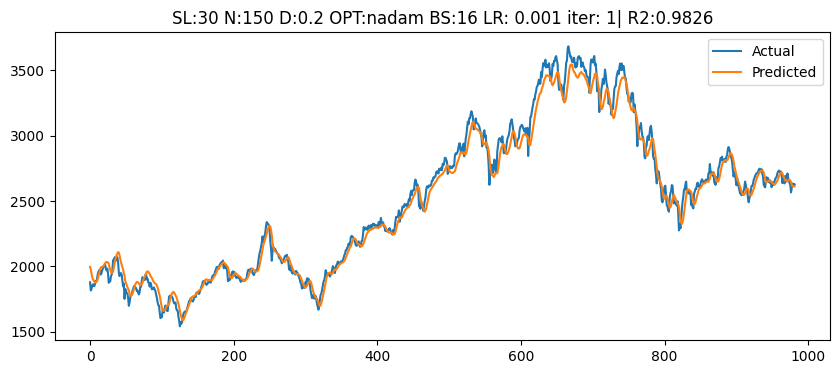

Training: SL=30, N=150, D=0.2, OPT=nadam, BS=16, LR = 0.001, ITER = 2


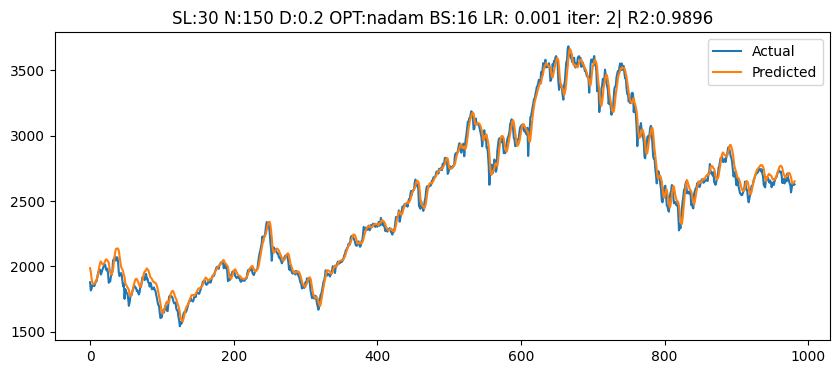

Training: SL=30, N=150, D=0.2, OPT=nadam, BS=16, LR = 0.001, ITER = 3


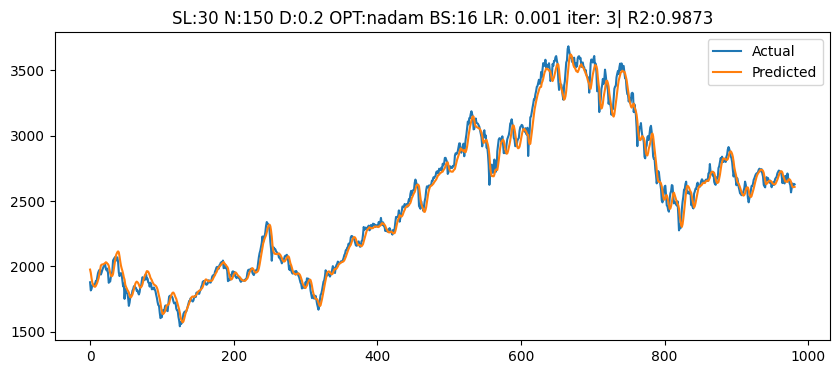

Training: SL=30, N=150, D=0.2, OPT=nadam, BS=8, LR = 0.01, ITER = 1


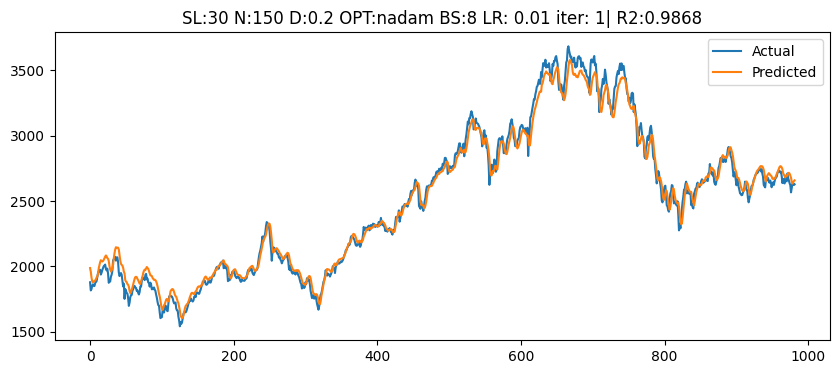

Training: SL=30, N=150, D=0.2, OPT=nadam, BS=8, LR = 0.01, ITER = 2


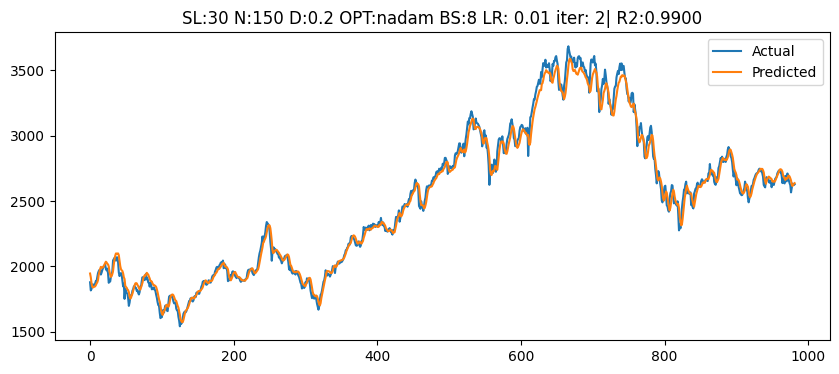

Training: SL=30, N=150, D=0.2, OPT=nadam, BS=8, LR = 0.01, ITER = 3


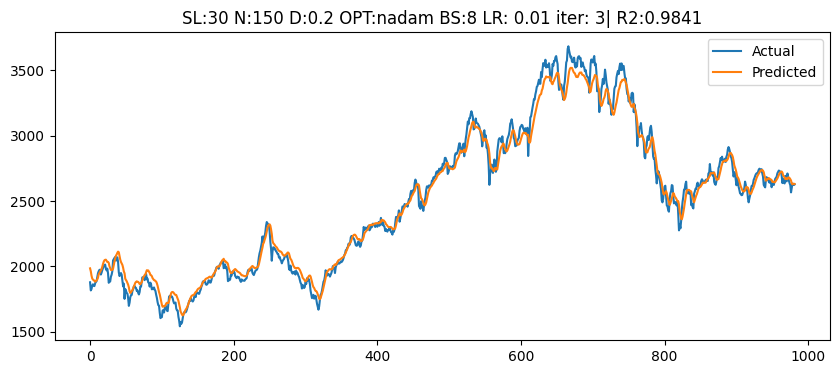

Training: SL=30, N=150, D=0.2, OPT=nadam, BS=16, LR = 0.01, ITER = 1


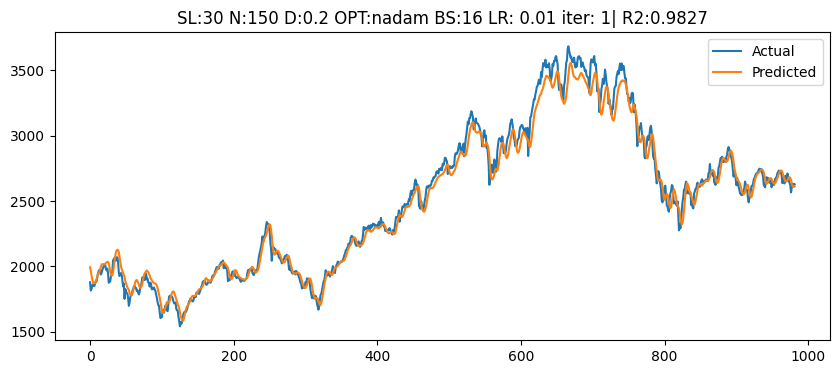

Training: SL=30, N=150, D=0.2, OPT=nadam, BS=16, LR = 0.01, ITER = 2


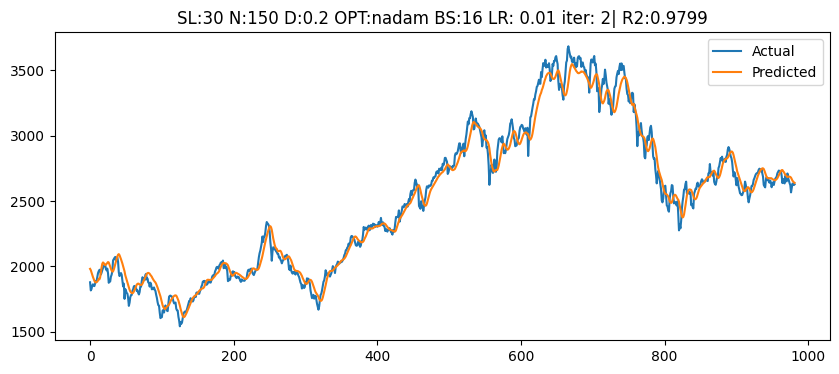

Training: SL=30, N=150, D=0.2, OPT=nadam, BS=16, LR = 0.01, ITER = 3


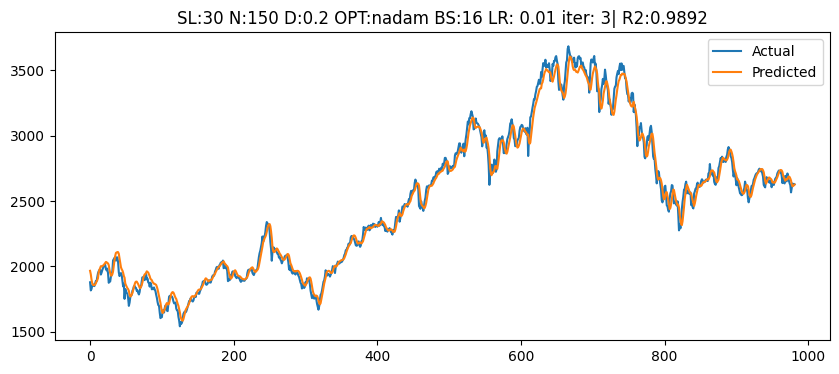

,SEQ_LENGTH,NEURONS,DROPOUT,OPTIMIZER,LEARNING_RATE,BATCH_SIZE,R2,MAE,MAPE,RMSE
6,30,150,0.2,adam,0.010,8,0.990733,0.011704,27.229029,0.014987
19,30,150,0.2,nadam,0.010,8,0.989995,0.011685,27.033480,0.015573
16,30,150,0.2,nadam,0.001,16,0.989641,0.011985,27.444338,0.015845
12,30,150,0.2,nadam,0.001,8,0.989515,0.012015,27.273061,0.015942
7,30,150,0.2,adam,0.010,8,0.989221,0.012632,27.290929,0.016164
23,30,150,0.2,nadam,0.010,16,0.989198,0.012203,27.041624,0.016181
5,30,150,0.2,adam,0.001,16,0.988622,0.012553,27.111390,0.016607
8,30,150,0.2,adam,0.010,8,0.987899,0.013363,26.832666,0.017126
17,30,150,0.2,nadam,0.001,16,0.987334,0.013279,27.087089,0.017521
1,30,150,0.2,adam,0.001,8,0.987139,0.013676,27.404569,0.017656


,SEQ_LENGTH,NEURONS,DROPOUT,OPTIMIZER,LEARNING_RATE,BATCH_SIZE,R2,MAE,MAPE,RMSE
2,30,150,0.2,adam,0.010,8,0.989284,0.012566,27.117541,0.016093
6,30,150,0.2,nadam,0.010,8,0.986972,0.013508,26.820726,0.017693
4,30,150,0.2,nadam,0.001,8,0.986632,0.013702,26.991703,0.017926
5,30,150,0.2,nadam,0.001,16,0.986539,0.013591,27.075364,0.017960
3,30,150,0.2,adam,0.010,16,0.985658,0.014229,26.874088,0.018615
0,30,150,0.2,adam,0.001,8,0.984626,0.014815,27.211311,0.019227
7,30,150,0.2,nadam,0.010,16,0.983933,0.014885,26.862144,0.019576
1,30,150,0.2,adam,0.001,16,0.977678,0.017583,26.752102,0.022705


In [ ]:
from tensorflow.keras.optimizers import Adam, Nadam

results = []

def get_optimizer(optimizer_name, learning_rate):
    if optimizer_name == 'adam':
        return Adam(learning_rate=learning_rate)
    elif optimizer_name == 'nadam':
        return Nadam(learning_rate=learning_rate)
    raise ValueError(f"Unknown optimizer: {optimizer_name}")


for SEQ_LENGTH in [30]:
    # Re-prepare sequences for current SEQ_LENGTH
    X, y = create_sequences(scaled_data, SEQ_LENGTH)
    split = int(0.8 * len(X))
    X_train, X_test = X[:split], X[split:]
    y_train, y_test = y[:split], y[split:]

    # for different number of neurons, perform hyperparameter tuning
    for NEURONS in [150]: # [50, 100, 150]
        for DROPOUT in [0.2]:
            for OPTIMIZER in ['adam', 'nadam']: # [adam, nadam]
                for LEARNING_RATE in [0.001, 0.01]: # [0.001, 0.01]
                    for BATCH_SIZE in [8, 16]:
                        for ITER in range(1, 4):
                            print(f'Training: SL={SEQ_LENGTH}, N={NEURONS}, D={DROPOUT}, OPT={OPTIMIZER}, BS={BATCH_SIZE}, LR = {LEARNING_RATE}, ITER = {ITER}')

                            # Build Model
                            model = Sequential([
                                Input(shape=(X_train.shape[1], X_train.shape[2])),
                                LSTM(NEURONS),
                                Dropout(DROPOUT),
                                Dense(1, activation='linear')
                            ])
                            model.compile(optimizer=get_optimizer(OPTIMIZER, LEARNING_RATE), loss='mean_squared_error')

                            # Train
                            early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
                            model.fit(X_train, y_train, epochs=50, batch_size=BATCH_SIZE,
                                      validation_data=(X_test, y_test), callbacks=[early_stop], verbose=0)

                            # Evaluate
                            y_pred = model.predict(X_test, verbose=0)
                            r2 = r2_score(y_test, y_pred)
                            mae = mean_absolute_error(y_test, y_pred)
                            mape = np.mean(np.abs((y_test - y_pred) / y_test)) * 100


                            rmse = np.sqrt(mean_squared_error(y_test, y_pred))

                            # Inverse Scale for plotting
                            y_test_inv = scaler.inverse_transform(np.concatenate([y_test.reshape(-1,1), np.zeros((len(y_test), len(features)-1))], axis=1))[:,0]
                            pred_inv = scaler.inverse_transform(np.concatenate([y_pred, np.zeros((len(y_pred), len(features)-1))], axis=1))[:,0]

                            # Plot and Save
                            plt.figure(figsize=(10, 4))
                            plt.plot(y_test_inv, label='Actual')
                            plt.plot(pred_inv, label='Predicted')
                            plt.title(f'SL:{SEQ_LENGTH} N:{NEURONS} D:{DROPOUT} OPT:{OPTIMIZER} BS:{BATCH_SIZE} LR: {LEARNING_RATE} iter: {ITER}| R2:{r2:.4f}')
                            plt.legend()
                            plt.savefig(f'plot_SL{SEQ_LENGTH}_N{NEURONS}_D{DROPOUT}_{OPTIMIZER}_LR{LEARNING_RATE}_BS{BATCH_SIZE}_ITER{ITER}.png')
                            plt.show()


                            results.append({
                                'SEQ_LENGTH': SEQ_LENGTH, 'NEURONS': NEURONS, 'DROPOUT': DROPOUT,
                                'OPTIMIZER': OPTIMIZER, 'LEARNING_RATE': LEARNING_RATE,
                                'BATCH_SIZE': BATCH_SIZE, 'R2': r2, 'MAE': mae, 'MAPE': mape, 'RMSE': rmse
                            })

# Convert results to DataFrame for easy viewing
results_df = pd.DataFrame(results)
display(results_df.sort_values(by='R2', ascending=False))

group_cols = ['SEQ_LENGTH', 'NEURONS', 'DROPOUT', 'OPTIMIZER', 'LEARNING_RATE', 'BATCH_SIZE']

avg_results = (
    results_df
    .groupby(group_cols)[['R2', 'MAE', 'MAPE', 'RMSE']]
    .mean()
    .reset_index()
    .sort_values(by='R2', ascending=False)
)

display(avg_results)

## MULTI LAYER

Training: N=(100, 50, 20), D=0.2, OPT=adam, BS=8, LR = 0.01, ITER = 1


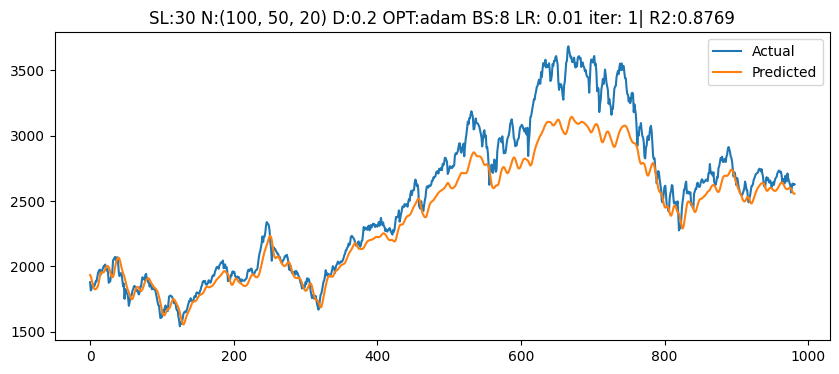

Training: N=(100, 50, 20), D=0.2, OPT=adam, BS=8, LR = 0.01, ITER = 2


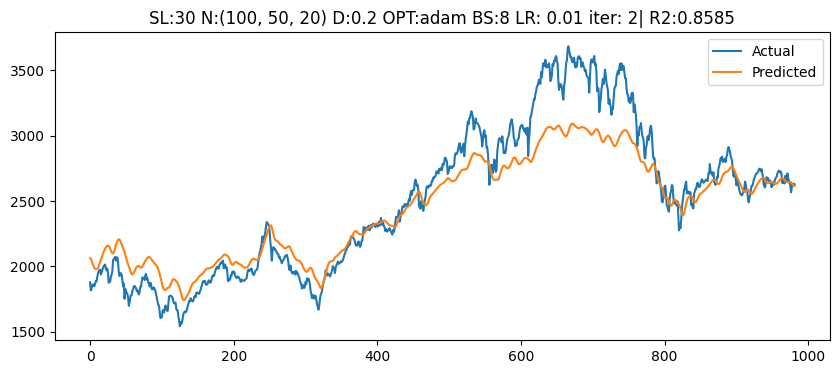

Training: N=(100, 50, 20), D=0.2, OPT=adam, BS=8, LR = 0.01, ITER = 3


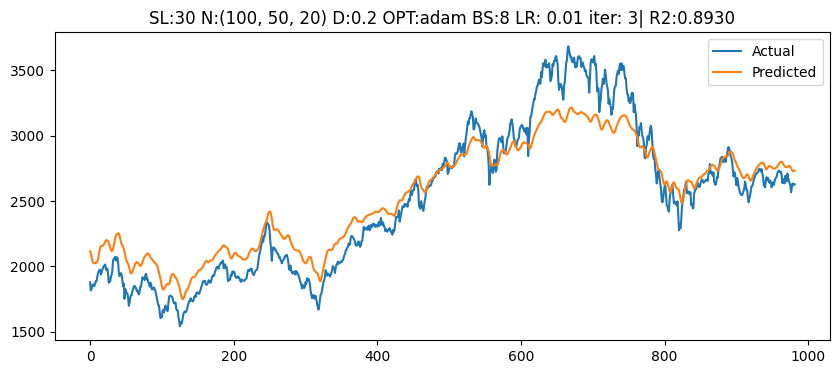

Training: N=(100, 50, 20), D=0.2, OPT=adam, BS=16, LR = 0.01, ITER = 1


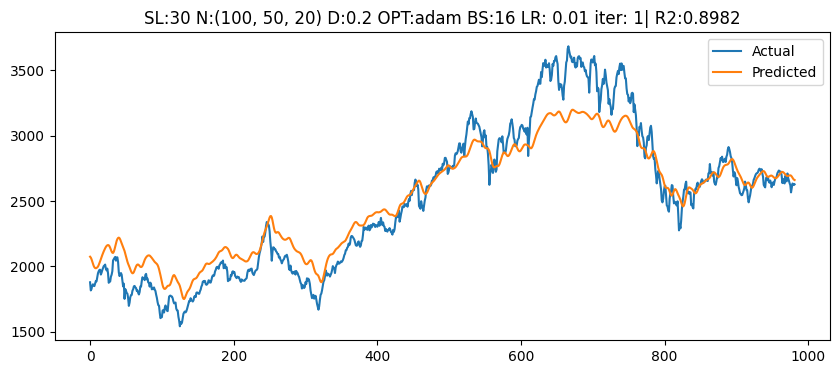

Training: N=(100, 50, 20), D=0.2, OPT=adam, BS=16, LR = 0.01, ITER = 2


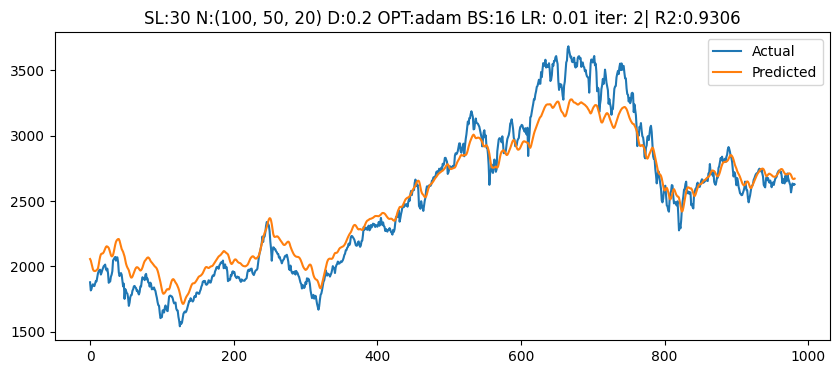

Training: N=(100, 50, 20), D=0.2, OPT=adam, BS=16, LR = 0.01, ITER = 3


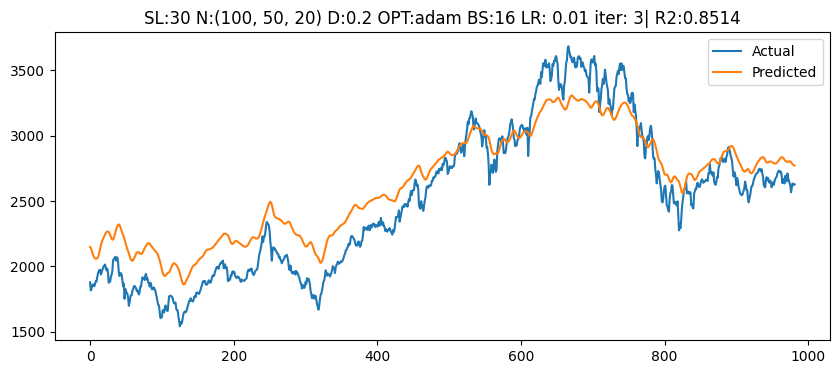

Training: N=(100, 50, 20), D=0.2, OPT=adam, BS=8, LR = 0.001, ITER = 1


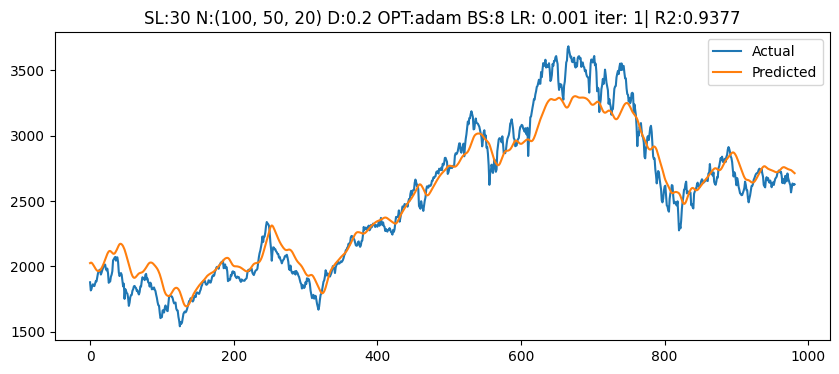

Training: N=(100, 50, 20), D=0.2, OPT=adam, BS=8, LR = 0.001, ITER = 2


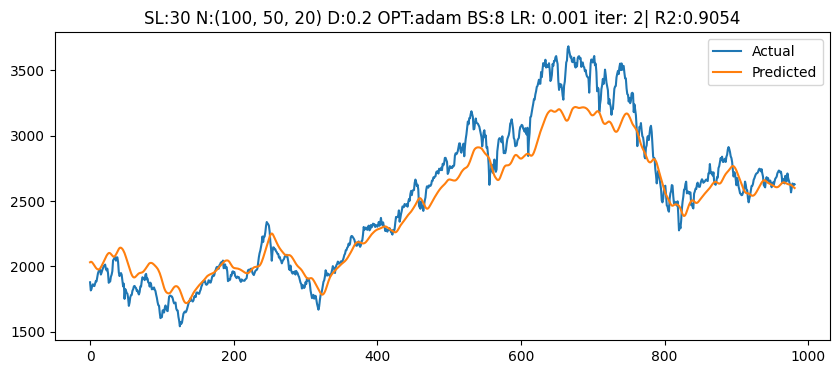

Training: N=(100, 50, 20), D=0.2, OPT=adam, BS=8, LR = 0.001, ITER = 3


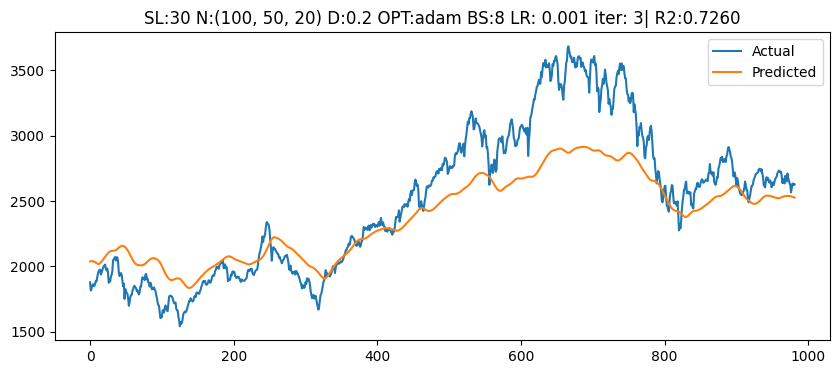

Training: N=(100, 50, 20), D=0.2, OPT=adam, BS=16, LR = 0.001, ITER = 1


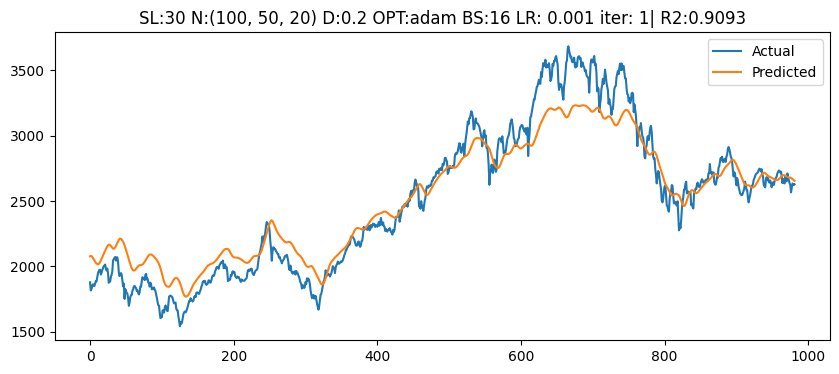

Training: N=(100, 50, 20), D=0.2, OPT=adam, BS=16, LR = 0.001, ITER = 2


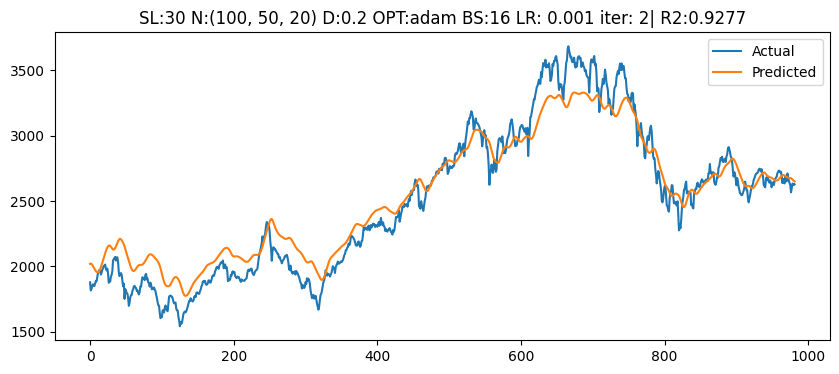

Training: N=(100, 50, 20), D=0.2, OPT=adam, BS=16, LR = 0.001, ITER = 3


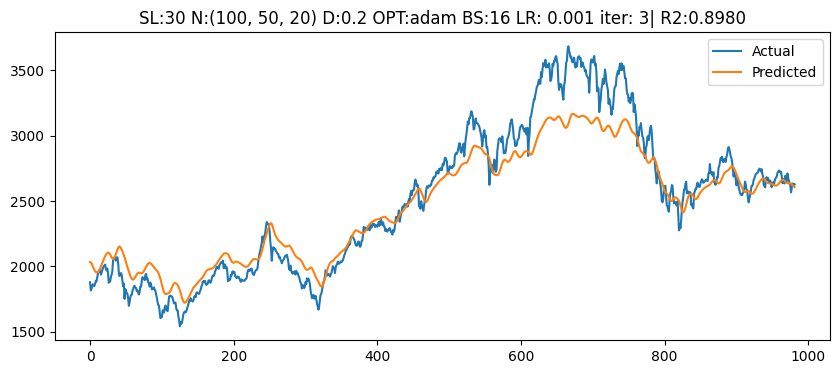

Training: N=(100, 50, 20), D=0.2, OPT=nadam, BS=8, LR = 0.01, ITER = 1


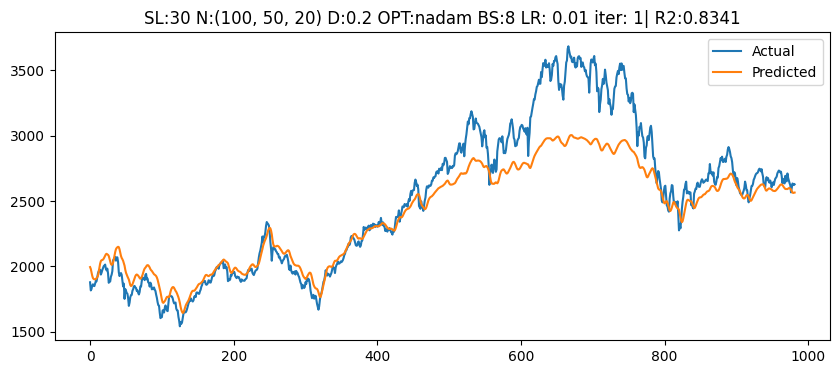

Training: N=(100, 50, 20), D=0.2, OPT=nadam, BS=8, LR = 0.01, ITER = 2


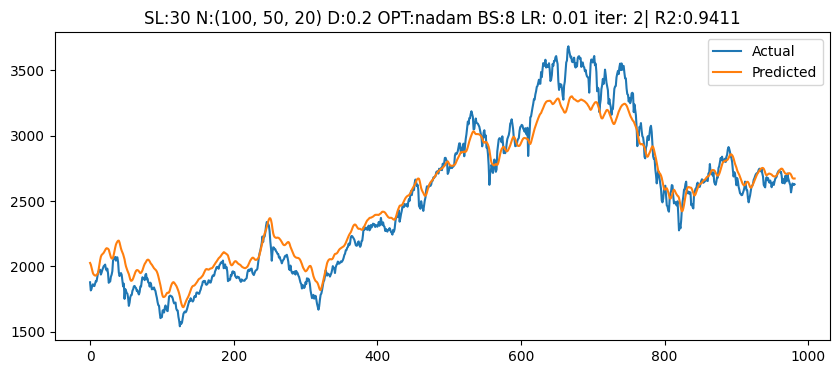

Training: N=(100, 50, 20), D=0.2, OPT=nadam, BS=8, LR = 0.01, ITER = 3


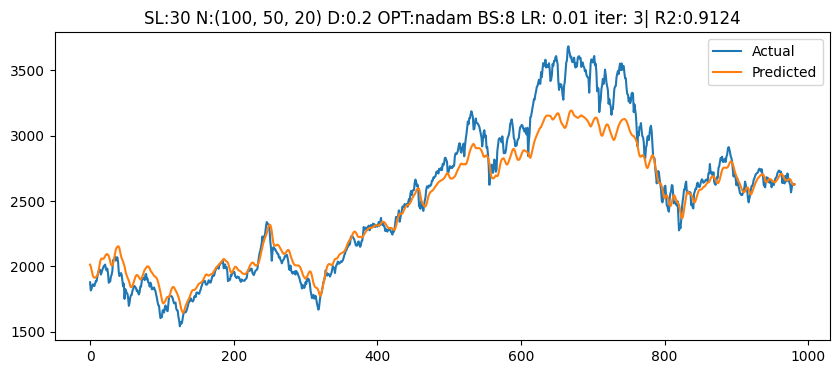

Training: N=(100, 50, 20), D=0.2, OPT=nadam, BS=16, LR = 0.01, ITER = 1


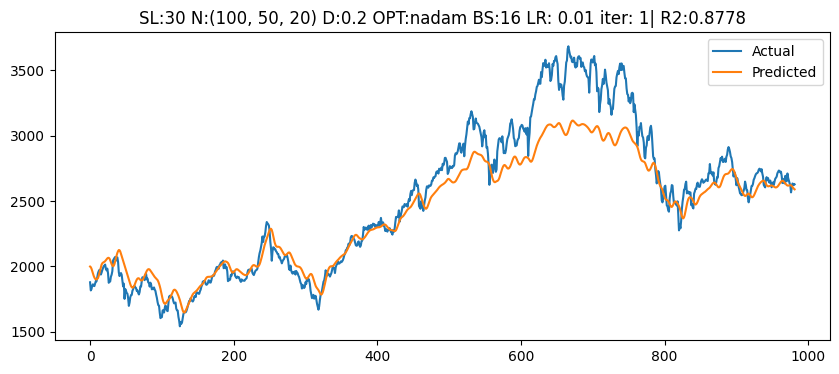

Training: N=(100, 50, 20), D=0.2, OPT=nadam, BS=16, LR = 0.01, ITER = 2


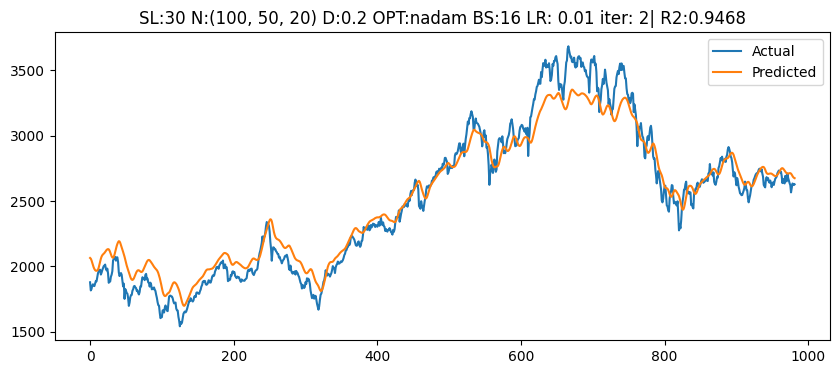

Training: N=(100, 50, 20), D=0.2, OPT=nadam, BS=16, LR = 0.01, ITER = 3


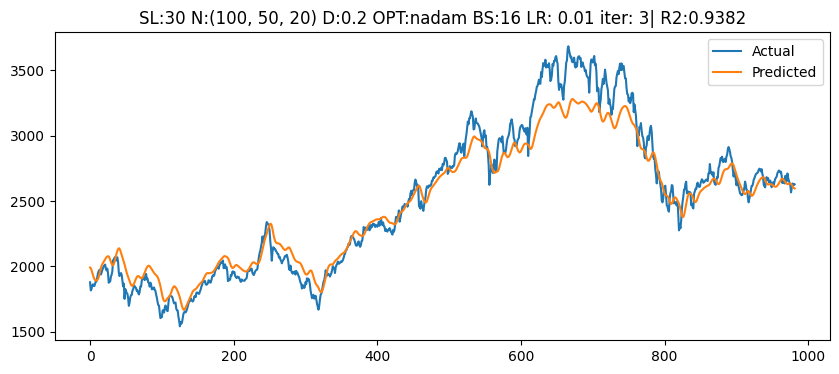

Training: N=(100, 50, 20), D=0.2, OPT=nadam, BS=8, LR = 0.001, ITER = 1


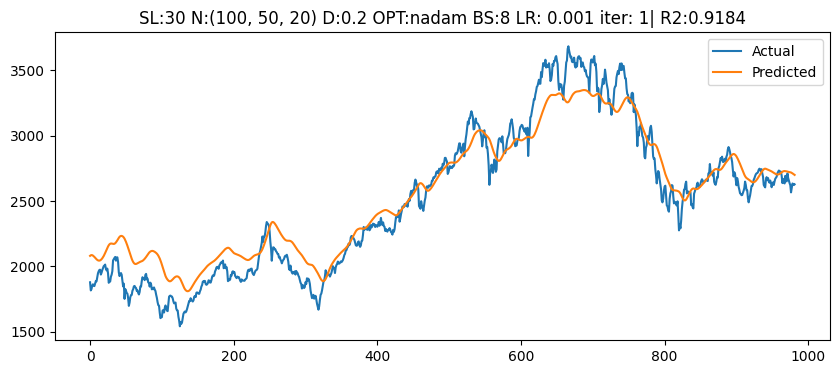

Training: N=(100, 50, 20), D=0.2, OPT=nadam, BS=8, LR = 0.001, ITER = 2


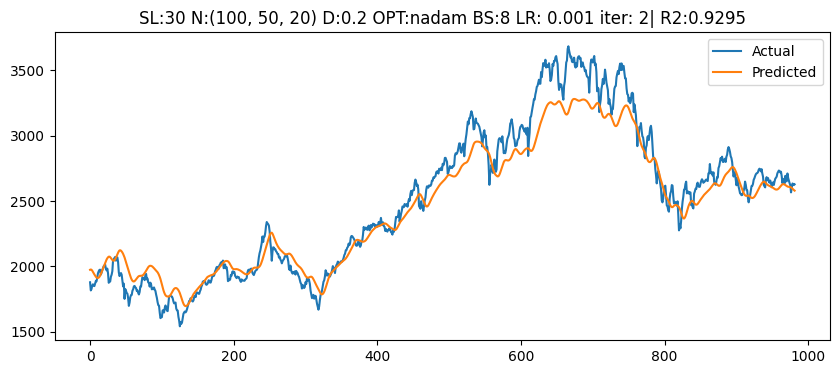

Training: N=(100, 50, 20), D=0.2, OPT=nadam, BS=8, LR = 0.001, ITER = 3


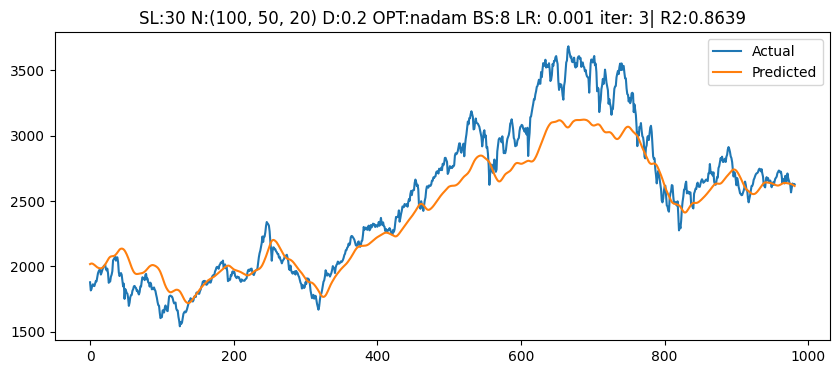

Training: N=(100, 50, 20), D=0.2, OPT=nadam, BS=16, LR = 0.001, ITER = 1


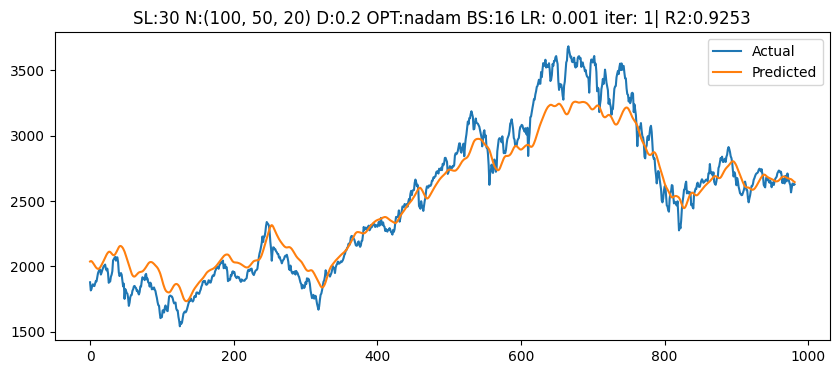

Training: N=(100, 50, 20), D=0.2, OPT=nadam, BS=16, LR = 0.001, ITER = 2


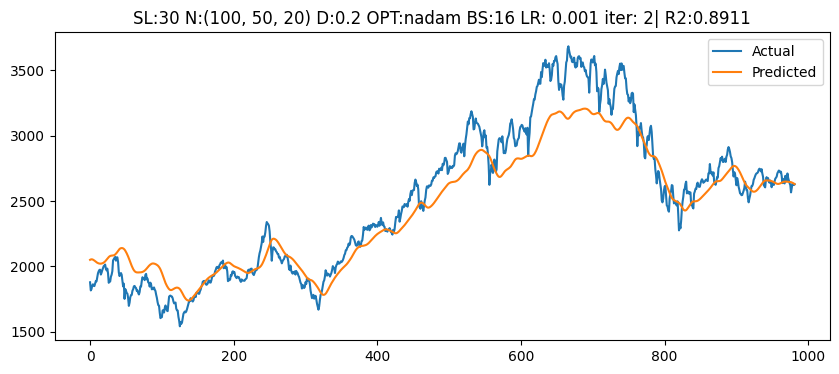

Training: N=(100, 50, 20), D=0.2, OPT=nadam, BS=16, LR = 0.001, ITER = 3


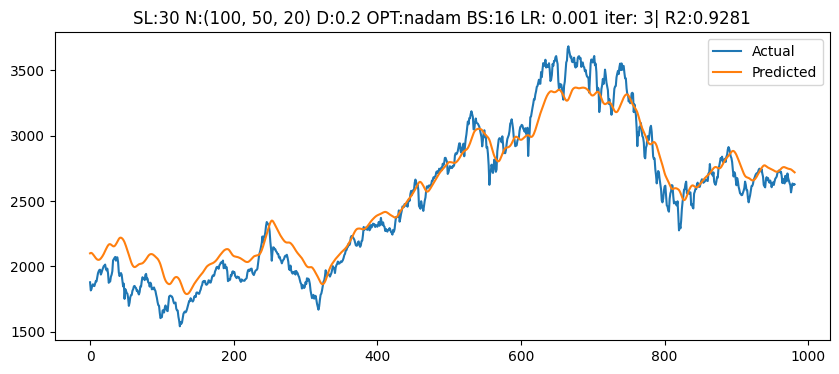

,SEQ_LENGTH,NEURONS,DROPOUT,OPTIMIZER,LEARNING_RATE,BATCH_SIZE,R2,MAE,MAPE,RMSE
16,30,"[100, 50, 20]",0.2,nadam,0.010,16,0.946777,0.028415,25.659604,0.035917
13,30,"[100, 50, 20]",0.2,nadam,0.010,8,0.941073,0.030022,25.426100,0.037793
17,30,"[100, 50, 20]",0.2,nadam,0.010,16,0.938240,0.029036,25.061364,0.038690
6,30,"[100, 50, 20]",0.2,adam,0.001,8,0.937706,0.029552,25.679570,0.038857
4,30,"[100, 50, 20]",0.2,adam,0.010,16,0.930612,0.032681,25.087561,0.041010
19,30,"[100, 50, 20]",0.2,nadam,0.001,8,0.929496,0.031544,24.933853,0.041339
23,30,"[100, 50, 20]",0.2,nadam,0.001,16,0.928117,0.033676,25.886669,0.041741
10,30,"[100, 50, 20]",0.2,adam,0.001,16,0.927726,0.033940,25.470094,0.041854
21,30,"[100, 50, 20]",0.2,nadam,0.001,16,0.925349,0.032922,24.973723,0.042537
18,30,"[100, 50, 20]",0.2,nadam,0.001,8,0.918375,0.035776,25.650878,0.044480


,SEQ_LENGTH,NEURONS,DROPOUT,OPTIMIZER,LEARNING_RATE,BATCH_SIZE,R2,MAE,MAPE,RMSE
7,30,"[100, 50, 20]",0.2,nadam,0.010,16,0.920928,0.031802,24.903595,0.043013
5,30,"[100, 50, 20]",0.2,nadam,0.001,16,0.914859,0.035418,25.113110,0.045217
1,30,"[100, 50, 20]",0.2,adam,0.001,16,0.911698,0.036165,24.838086,0.046149
4,30,"[100, 50, 20]",0.2,nadam,0.001,8,0.903929,0.036809,24.869458,0.047750
6,30,"[100, 50, 20]",0.2,nadam,0.010,8,0.895858,0.035299,24.416092,0.049095
3,30,"[100, 50, 20]",0.2,adam,0.010,16,0.893419,0.041897,25.161334,0.050230
2,30,"[100, 50, 20]",0.2,adam,0.010,8,0.876139,0.042019,24.301527,0.054703
0,30,"[100, 50, 20]",0.2,adam,0.001,8,0.856385,0.042911,24.118146,0.056076


In [ ]:
from tensorflow.keras.optimizers import Adam, Nadam

results = []

def get_optimizer(optimizer_name, learning_rate):
    if optimizer_name == 'adam':
        return Adam(learning_rate=learning_rate)
    elif optimizer_name == 'nadam':
        return Nadam(learning_rate=learning_rate)
    raise ValueError(f"Unknown optimizer: {optimizer_name}")


# ARCHITECTURES = [(50, 20), (100, 50), (150, 100), (100, 50, 20)]
ARCHITECTURES = [(100, 50, 20)]

SEQ_LENGTH = 30

# Re-prepare sequences for current SEQ_LENGTH
X, y = create_sequences(scaled_data, SEQ_LENGTH)
split = int(0.8 * len(X))
X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]


for LAYERS in ARCHITECTURES:
# for different number of neurons, perform hyperparameter tuning
    for DROPOUT in [0.2]:
        for OPTIMIZER in ['adam', 'nadam']: # [adam, nadam]
            for LEARNING_RATE in [0.01, 0.001]: # [0.01, 0.001]
                for BATCH_SIZE in [8, 16]:
                    for ITER in range(1, 4):
                        print(f'Training: N={LAYERS}, D={DROPOUT}, OPT={OPTIMIZER}, BS={BATCH_SIZE}, LR = {LEARNING_RATE}, ITER = {ITER}')

                        # Build Model
                        model  = Sequential()
                        model.add(Input(shape=(X_train.shape[1], X_train.shape[2])))

                        for i, neurons in enumerate(LAYERS):
                            is_last_lstm = (i == len(LAYERS) - 1)
                            model.add(LSTM(neurons, return_sequences=not is_last_lstm))
                            model.add(Dropout(DROPOUT))

                        model.add(Dense(1, activation='linear'))

                        model.compile(optimizer=get_optimizer(OPTIMIZER, LEARNING_RATE), loss='mean_squared_error')

                        # Train
                        early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
                        model.fit(X_train, y_train, epochs=50, batch_size=BATCH_SIZE,
                                    validation_data=(X_test, y_test), callbacks=[early_stop], verbose=0)

                        # Evaluate
                        y_pred = model.predict(X_test, verbose=0)
                        r2 = r2_score(y_test, y_pred)
                        mae = mean_absolute_error(y_test, y_pred)
                        mape = np.mean(np.abs((y_test - y_pred) / y_test)) * 100


                        rmse = np.sqrt(mean_squared_error(y_test, y_pred))

                        # Inverse Scale for plotting
                        y_test_inv = scaler.inverse_transform(np.concatenate([y_test.reshape(-1,1), np.zeros((len(y_test), len(features)-1))], axis=1))[:,0]
                        pred_inv = scaler.inverse_transform(np.concatenate([y_pred, np.zeros((len(y_pred), len(features)-1))], axis=1))[:,0]

                        # Plot and Save
                        plt.figure(figsize=(10, 4))
                        plt.plot(y_test_inv, label='Actual')
                        plt.plot(pred_inv, label='Predicted')
                        plt.title(f'SL:{SEQ_LENGTH} N:{LAYERS} D:{DROPOUT} OPT:{OPTIMIZER} BS:{BATCH_SIZE} LR: {LEARNING_RATE} iter: {ITER}| R2:{r2:.4f}')
                        plt.legend()
                        plt.savefig(f'plot_SL{SEQ_LENGTH}_N{LAYERS}_D{DROPOUT}_{OPTIMIZER}_LR{LEARNING_RATE}_BS{BATCH_SIZE}_ITER{ITER}.png')
                        plt.show()


                        results.append({
                            'SEQ_LENGTH': SEQ_LENGTH, 'NEURONS': LAYERS, 'DROPOUT': DROPOUT,
                            'OPTIMIZER': OPTIMIZER, 'LEARNING_RATE': LEARNING_RATE,
                            'BATCH_SIZE': BATCH_SIZE, 'R2': r2, 'MAE': mae, 'MAPE': mape, 'RMSE': rmse
                        })

# Convert results to DataFrame for easy viewing
results_df = pd.DataFrame(results)
display(results_df.sort_values(by='R2', ascending=False))

group_cols = ['SEQ_LENGTH', 'NEURONS', 'DROPOUT', 'OPTIMIZER', 'LEARNING_RATE', 'BATCH_SIZE']

avg_results = (
    results_df
    .groupby(group_cols)[['R2', 'MAE', 'MAPE', 'RMSE']]
    .mean()
    .reset_index()
    .sort_values(by='R2', ascending=False)
)

display(avg_results)